<a href="https://colab.research.google.com/github/nahsiz/99_days_of_coding_MLOps_With_CPC/blob/main/phase-1/day_16/day_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Required Libraries

Text Box Title: Importing Required Libraries

Text Box Description: Import Pandas, NumPy, Matplotlib, and Seaborn for data analysis and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load the Dataset

Text Box Title: Loading the Air Pollution Dataset

Text Box Description: Load the CSV file into a Pandas DataFrame and strip any extra whitespace from column names so names like PM2.5 and PM10 work correctly.

In [2]:
data = pd.read_csv('/content/updated_pollution_dataset.csv')
data.columns = data.columns.str.strip()

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


3. Display First 5 Rows

Text Box Title: Displaying the First 5 Rows

Text Box Description: Use the head() function to quickly verify the dataset was loaded correctly.

In [3]:
data.head()

,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303,Good


4. Select Four Columns (Shared X-Axis)

Text Box Title: Selecting Four Columns for Correlation Analysis

Text Box Description: Select one shared x-axis column (Temperature) and three y-axis columns (PM2.5, PM10, CO). Temperature will stay on the x-axis in all scatter plots so the three relationships can be compared against the same horizontal axis.

In [4]:
x_col = 'Temperature'
y_col_1 = 'PM2.5'
y_col_2 = 'PM10'
y_col_3 = 'CO'

selected_data = data[[x_col, y_col_1, y_col_2, y_col_3]]

selected_data.head()

,Temperature,PM2.5,PM10,CO
0,29.8,5.2,17.9,1.72
1,28.3,2.3,12.2,1.64
2,23.1,26.7,33.8,1.63
3,27.1,6.1,6.3,1.15
4,26.5,6.9,16.0,1.01


5. Calculate Pearson Correlation

Text Box Title: Calculating Correlation Between Four Columns

Text Box Description: Calculate the Pearson correlation coefficient three times — Temperature vs PM2.5, Temperature vs PM10, and Temperature vs CO. Temperature remains the shared x-axis column in all three calculations.

In [5]:
correlation_1 = selected_data[x_col].corr(selected_data[y_col_1])
correlation_2 = selected_data[x_col].corr(selected_data[y_col_2])
correlation_3 = selected_data[x_col].corr(selected_data[y_col_3])

print("Correlation between", x_col, "and", y_col_1)
print("Pearson Correlation Coefficient:", round(correlation_1, 4))
print()
print("Correlation between", x_col, "and", y_col_2)
print("Pearson Correlation Coefficient:", round(correlation_2, 4))
print()
print("Correlation between", x_col, "and", y_col_3)
print("Pearson Correlation Coefficient:", round(correlation_3, 4))

Correlation between Temperature and PM2.5
Pearson Correlation Coefficient: 0.3238

Correlation between Temperature and PM10
Pearson Correlation Coefficient: 0.4257

Correlation between Temperature and CO
Pearson Correlation Coefficient: 0.6853


6. Correlation Heatmap (4×4)

Text Box Title: Visualizing Correlation Using a Heatmap

Text Box Description: Create a 4×4 heatmap to display the correlation coefficients between all four selected columns at a glance.

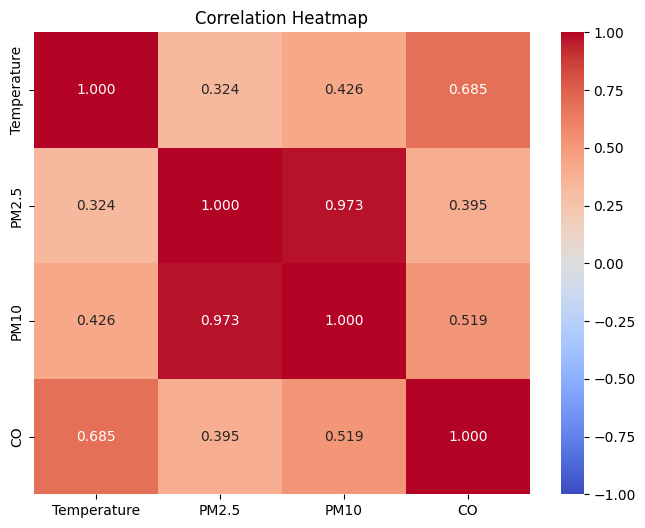

In [6]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    selected_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.show()

7. Scatter Plot — Shared X with First Y

Text Box Title: Visualizing Temperature vs PM2.5

Text Box Description: Create a scatter plot with a regression line where Temperature is on the x-axis and PM2.5 is on the y-axis. Temperature stays on the x-axis because it is the shared axis for all three plots.

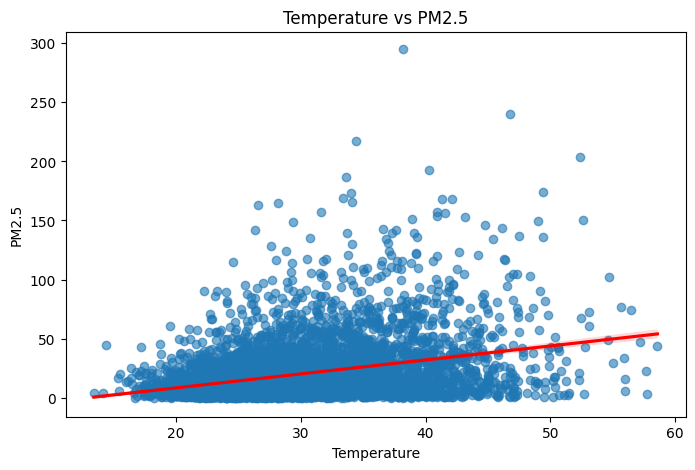

In [7]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_1,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_1}')
plt.xlabel(x_col)
plt.ylabel(y_col_1)
plt.show()

8. Scatter Plot — Shared X with Second Y

Text Box Title: Visualizing Temperature vs PM10

Text Box Description: Create a scatter plot with a regression line where Temperature is again on the x-axis, but PM10 is now on the y-axis. The x-axis stays identical to the previous plot so both relationships share the same horizontal axis.

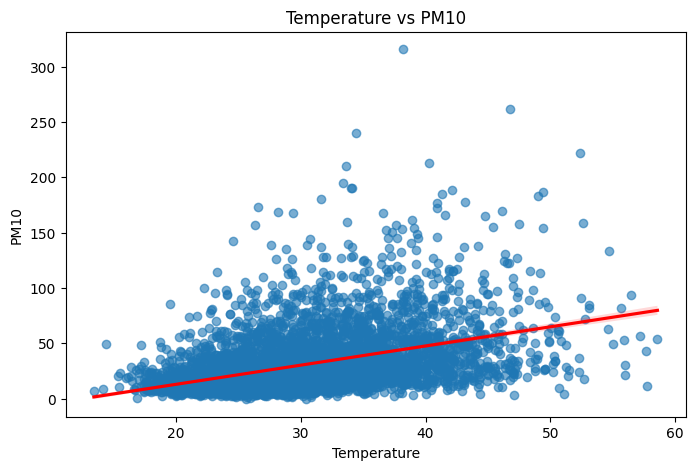

In [8]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_2,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_2}')
plt.xlabel(x_col)
plt.ylabel(y_col_2)
plt.show()

9. Scatter Plot — Shared X with Third Y

Text Box Title: Visualizing Temperature vs CO

Text Box Description: Create a scatter plot with a regression line where Temperature is again on the x-axis, but CO is now on the y-axis. The x-axis stays identical so all three plots share the same horizontal axis.

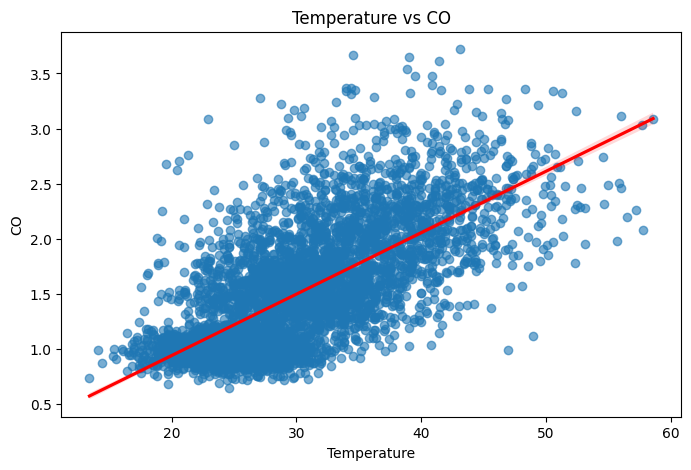

In [9]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=selected_data,
    x=x_col,
    y=y_col_3,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title(f'{x_col} vs {y_col_3}')
plt.xlabel(x_col)
plt.ylabel(y_col_3)
plt.show()

10. Interpret the First Correlation Result

Text Box Title: Interpreting the First Correlation Coefficient

Text Box Description: Identify whether the relationship between Temperature and PM2.5 is positive, negative, or has no linear correlation.

In [10]:
if correlation_1 > 0:
    print("Positive Correlation")
elif correlation_1 < 0:
    print("Negative Correlation")
else:
    print("No Linear Correlation")

print("Correlation Value:", round(correlation_1, 4))

Positive Correlation
Correlation Value: 0.3238


11. Interpret the Second Correlation Result

Text Box Title: Interpreting the Second Correlation Coefficient

Text Box Description: Identify whether the relationship between Temperature and PM10 is positive, negative, or has no linear correlation.

In [11]:
if correlation_2 > 0:
    print("Positive Correlation")
elif correlation_2 < 0:
    print("Negative Correlation")
else:
    print("No Linear Correlation")

print("Correlation Value:", round(correlation_2, 4))

Positive Correlation
Correlation Value: 0.4257


12. Interpret the Third Correlation Result

Text Box Title: Interpreting the Third Correlation Coefficient

Text Box Description: Identify whether the relationship between Temperature and CO is positive, negative, or has no linear correlation.

In [12]:
if correlation_3 > 0:
    print("Positive Correlation")
elif correlation_3 < 0:
    print("Negative Correlation")
else:
    print("No Linear Correlation")

print("Correlation Value:", round(correlation_3, 4))

Positive Correlation
Correlation Value: 0.6853


13. Display Final Correlation Result

Text Box Title: Final Correlation Analysis Result

Text Box Description: Display the shared x-axis column name and all three y-axis column names along with their calculated Pearson correlation coefficients.

In [13]:
print("Final Correlation Analysis")
print("--------------------------")

print("Shared X-Axis Column :", x_col)
print("First Y-Axis Column  :", y_col_1)
print("Pearson Correlation  :", round(correlation_1, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Second Y-Axis Column :", y_col_2)
print("Pearson Correlation  :", round(correlation_2, 4))
print()

print("Shared X-Axis Column :", x_col)
print("Third Y-Axis Column  :", y_col_3)
print("Pearson Correlation  :", round(correlation_3, 4))

Final Correlation Analysis
--------------------------
Shared X-Axis Column : Temperature
First Y-Axis Column  : PM2.5
Pearson Correlation  : 0.3238

Shared X-Axis Column : Temperature
Second Y-Axis Column : PM10
Pearson Correlation  : 0.4257

Shared X-Axis Column : Temperature
Third Y-Axis Column  : CO
Pearson Correlation  : 0.6853
